# Hypothesis 1

Physical activity influenced by weather

## Reading patient data

In [ ]:
import pandas as pd, matplotlib.pyplot as mpl
from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

# Define the path to the folder containing the sensor data
folder_path = '/content/drive/My Drive/Colab Notebooks/IVDA/Hourly Sensor Data'

# Initialize an empty list to store patient data
patients = []

# Check if the folder exists
if os.path.exists(folder_path):
    # List all files in the directory
    for filename in os.listdir(folder_path):
        # Construct the full file path
        file_path = os.path.join(folder_path, filename)
        # Ensure it's a file and not a directory
        if os.path.isfile(file_path):
            try:
                # Extract patient ID from filename (assuming 'RHourly_XXXX.csv' format)
                patient_id = filename[-8:-4]

                if patient_id != '4063':

                    # Read the CSV file into a DataFrame
                    patient_data_df = pd.read_csv(file_path)

                    # Create a dictionary for the patient with their ID and data
                    patient_entry = {
                        "id": patient_id,
                        "data": patient_data_df
                    }

                    # Append the patient entry to the patients list
                    patients.append(patient_entry)
                    print(f"Successfully loaded {filename} with ID {patient_id}")
            except Exception as e:
                print(f"Error loading {filename}: {e}")
else:
    print(f"Error: Folder not found at {folder_path}")

# You can now access the data for each patient in the 'patients' list.
# For example, patients[0]['id'] for the ID and patients[0]['data'] for the DataFrame from the first file.


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Successfully loaded RHourly_1971.csv with ID 1971
Successfully loaded RHourly_8046.csv with ID 8046
Successfully loaded RHourly_3389.csv with ID 3389
Successfully loaded RHourly_9173.csv with ID 9173
Successfully loaded RHourly_2676.csv with ID 2676
Successfully loaded RHourly_9085.csv with ID 9085
Successfully loaded RHourly_7016.csv with ID 7016
Successfully loaded RHourly_4475.csv with ID 4475
Successfully loaded RHourly_4349.csv with ID 4349
Successfully loaded RHourly_5977.csv with ID 5977
Successfully loaded RHourly_2815.csv with ID 2815
Successfully loaded RHourly_7513.csv with ID 7513
Successfully loaded RHourly_8826.csv with ID 8826
Successfully loaded RHourly_7458.csv with ID 7458
Successfully loaded RHourly_7928.csv with ID 7928
Successfully loaded RHourly_3405.csv with ID 3405
Successfully loaded RHourly_7996.csv with ID 7996
Successfully loaded R

In [ ]:
print(len(patients), '\n\n', patients[0])

43 

 {'id': '1971', 'data':                      time       steps  sleep  heartrate
0     2021-09-02 00:00:00    0.000000      0        NaN
1     2021-09-02 01:00:00    0.000000      0        NaN
2     2021-09-02 02:00:00    0.000000      0        NaN
3     2021-09-02 03:00:00    0.000000      0        NaN
4     2021-09-02 04:00:00    0.000000      0        NaN
...                   ...         ...    ...        ...
1579  2021-11-06 19:00:00  145.292480      0  73.263080
1580  2021-11-06 20:00:00  169.162960      0  71.342678
1581  2021-11-06 21:00:00   23.582556      0  69.773770
1582  2021-11-06 22:00:00  135.176160      0  65.896477
1583  2021-11-06 23:00:00  239.247990      0  66.885023

[1584 rows x 4 columns]}


## Reading weather data

In [ ]:
weather_data_df = pd.read_csv('/content/drive/My Drive/Colab Notebooks/IVDA/weather_data_2021.csv')
print(weather_data_df)
#
# print(os.listdir('/content/drive/My Drive/Colab Notebooks/IVDA/'))

    reference_timestamp  Air temperature 2 m above ground; daily mean  \
0      01.01.2021 00:00                                           0.9   
1      02.01.2021 00:00                                           0.5   
2      03.01.2021 00:00                                          -0.6   
3      04.01.2021 00:00                                          -1.1   
4      05.01.2021 00:00                                          -1.5   
..                  ...                                           ...   
360    27.12.2021 00:00                                           5.0   
361    28.12.2021 00:00                                           6.9   
362    29.12.2021 00:00                                           8.0   
363    30.12.2021 00:00                                          11.2   
364    31.12.2021 00:00                                           8.2   

     Air temperature 2 m above ground; daily maximum  \
0                                                1.8   
1          

## Plotting and correlating

/tmp/ipykernel_3227/2412982355.py:63: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.



   Patient_ID  Correlation Steps-Temperature
16       7996                        -0.6013
31       2909                        -0.5105
37       6661                        -0.4016
3        9173                        -0.2870
26       4457                        -0.2060
13       7458                        -0.2048
1        8046                        -0.1907
4        2676                        -0.1879
2        3389                        -0.1383
35       7183                        -0.1377
33       9411                        -0.1301
11       7513                        -0.0701
5        9085                        -0.0331
19       6947                        -0.0055
38       6155                         0.0094
12       8826                         0.0156
14       7928                         0.0244
20       2854                         0.0280
23       4420                         0.0653
40       2130                         0.0755
10       2815                         0.1127
29       6

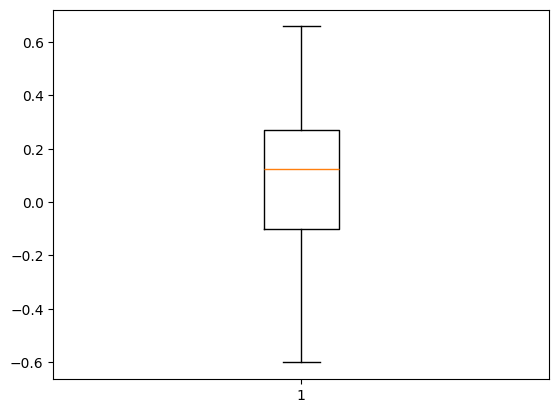

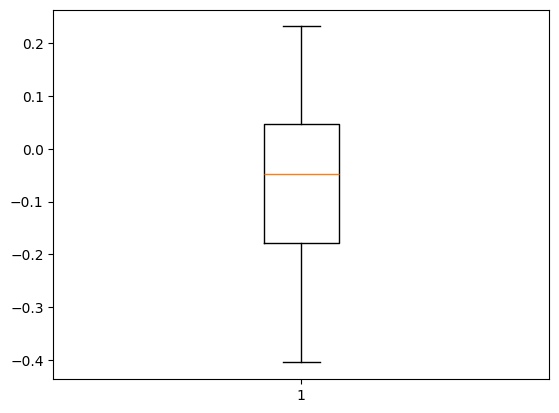

In [ ]:
import numpy as np
np.set_printoptions(legacy='1.25')
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

import seaborn as sns

# Pre-process weather data once outside the loop
df_weather_processed = weather_data_df.copy()
df_weather_processed.rename(columns={
    'reference_timestamp': 'Date',
    'Air temperature 2 m above ground; daily maximum': 'Max_Temperature',
    'Precipitation; daily total 0 UTC - 0 UTC': 'Precipitation'
}, inplace=True)
df_weather_processed['Date'] = pd.to_datetime(df_weather_processed['Date'], format='%d.%m.%Y %H:%M')
daily_max_temp_df = df_weather_processed[['Date', 'Max_Temperature']].copy()
daily_max_temp_df = daily_max_temp_df.groupby('Date')['Max_Temperature'].max().reset_index()
daily_max_temp_df['Precipitation'] = df_weather_processed.groupby('Date')['Precipitation'].max().reset_index()['Precipitation']

# corr_dict={}
corr_df = pd.DataFrame(columns=['Patient_ID', 'Correlation Steps-Temperature', 'Correlation Steps-Precipitation'])

# Calculate global min/max temperature from daily_max_temp_df (weather data only)
global_min_temp = daily_max_temp_df['Max_Temperature'].min() - 1 # Add padding
global_max_temp = daily_max_temp_df['Max_Temperature'].max() + 1 # Add padding

global_max_pp = daily_max_temp_df['Precipitation'].max() + 1 # Add padding
# global_min_pp = daily_max_temp_df['Precipitation'].min() - 1 # Add padding

# Define grid dimensions
rows = 7
cols = 7

# Create a single Plotly figure with subplots
# `specs` are needed to enable secondary_y for each subplot
specs = [[{"secondary_y": True}] * cols for _ in range(rows)]
fig_temp = make_subplots(rows=rows, cols=cols, shared_xaxes=False, vertical_spacing=0.05, horizontal_spacing=0.02, specs=specs)
fig_pp = make_subplots(rows=rows, cols=cols, shared_xaxes=False, vertical_spacing=0.02, horizontal_spacing=0.05, specs=specs)

# Loop through each patient to add traces to the subplots
for idx, patient_entry in enumerate(patients):
    patient_id = patient_entry['id']
    patient_data = patient_entry['data']

    current_row = (idx // cols) + 1
    current_col = (idx % cols) + 1

    # Process patient data for daily steps
    df_patient = patient_data.copy()
    df_patient['time'] = pd.to_datetime(df_patient['time'])
    daily_steps_df = df_patient.set_index('time').resample('D')['steps'].sum().reset_index()
    daily_steps_df.rename(columns={'time': 'Date'}, inplace=True)

    # Merge daily steps with daily max temperature
    merged_df = pd.merge(daily_steps_df, daily_max_temp_df, on='Date', how='inner')
    merged_df.sort_values(by='Date', inplace=True)

    correlation_temp = merged_df['steps'].corr(merged_df['Max_Temperature'])
    correlation_pp = merged_df['steps'].corr(merged_df['Precipitation'])
    # corr_dict[patient_id] = round(correlation, 4)

    corr_df = pd.concat([corr_df, pd.DataFrame({'Patient_ID': [patient_id], 'Correlation Steps-Temperature': [round(correlation_temp, 4)], 'Correlation Steps-Precipitation': [round(correlation_pp, 4)]})], ignore_index=True)

    # # Skip plotting if merged_df is empty (no overlapping data) without explicit error message
    # if merged_df.empty:
    #     # Add a placeholder annotation for empty subplots
    #     fig.add_annotation(xref="x domain", yref="y domain", # Use domain for relative positioning within subplot
    #                        x=0.5, y=0.5, text=f"No data for {patient_id}", showarrow=False,
    #                        row=current_row, col=current_col,
    #                        font=dict(size=10, color="gray"))
    #     continue

    # Add trace for daily maximum temperature (secondary y-axis)
    fig_temp.add_trace(
        go.Scatter(x=merged_df['Date'], y=merged_df['Max_Temperature'], mode='lines+markers', name='Max Temperature (°C)', line=dict(color='maroon'), showlegend=False),
        row=current_row, col=current_col, secondary_y=True
    )

    fig_pp.add_trace(
        go.Scatter(x=merged_df['Date'], y=merged_df['Precipitation'], mode='lines+markers', name='Precipitation (mm)', line=dict(color='deepskyblue'), showlegend=False),
        row=current_row, col=current_col, secondary_y=True
    )

    # Add trace for daily steps (primary y-axis)
    fig_temp.add_trace(
        go.Scatter(x=merged_df['Date'], y=merged_df['steps'], mode='lines+markers', name='Daily Steps', line=dict(color='green'), zorder=1, showlegend=False),
        row=current_row, col=current_col, secondary_y=False
    )

    fig_pp.add_trace(
        go.Scatter(x=merged_df['Date'], y=merged_df['steps'], mode='lines+markers', name='Daily Steps', line=dict(color='green'), zorder=1, showlegend=False),
        row=current_row, col=current_col, secondary_y=False
    )

    # # Generate and add alternating day backgrounds for this subplot
    # bg_shapes = generate_alternating_day_background_shapes(merged_df.rename(columns={'Date': 'time'}), steps_y_min=-500, steps_y_max=30000)
    # for shape in bg_shapes:
    #     fig.add_shape(shape, row=current_row, col=current_col)

    # Update layout for this specific subplot
    fig_temp.update_xaxes(title_text='Time', showticklabels=False, row=current_row, col=current_col)
    fig_temp.update_yaxes(showticklabels=False, secondary_y=False, range=[-500, 30000], row=current_row, col=current_col)
    fig_temp.update_yaxes(showticklabels=False, secondary_y=True, range=[global_min_temp, global_max_temp], row=current_row, col=current_col)
    if current_col == 1:
        fig_temp.update_yaxes(title_text='Total Steps per Day', showticklabels=True, secondary_y=False, row=current_row, col=current_col)
    if current_col == 5:
        fig_temp.update_yaxes(title_text='Max Temperature (°C)', showticklabels=True, secondary_y=True, row=current_row, col=current_col)
    # if current_col != 1:
    #     fig.update_yaxes(showticklabels=False, secondary_y = False)
    # if current_col != 5:
    #     fig.update_yaxes(showticklabels=False, secondary_y = True)

    fig_pp.update_xaxes(title_text='Time', showticklabels=False, row=current_row, col=current_col)
    fig_pp.update_yaxes(secondary_y=False, range=[-500, 30000], row=current_row, col=current_col, )
    fig_pp.update_yaxes(secondary_y=True, range=[0, global_max_pp], row=current_row, col=current_col)
    if current_col == 1:
        fig_pp.update_yaxes(title_text='Total Steps per Day', secondary_y=False, row=current_row, col=current_col)
    if current_col == cols:
        fig_pp.update_yaxes(title_text='Precipitation (mm)', secondary_y=True, row=current_row, col=current_col)

    # Set subplot title
    fig_temp.add_annotation(
        x=0.5,
        y=1.0,
        xref="x domain", # Referencing the x-domain of the current subplot
        yref="y domain", # Referencing the y-domain of the current subplot
        text=f"Patient {patient_id}",
        showarrow=False,
        font=dict(size=10),
        yshift=10,
        row=current_row,
        col=current_col
    )

    fig_pp.add_annotation(
        x=0.5,
        y=1.0,
        xref="x domain", # Referencing the x-domain of the current subplot
        yref="y domain", # Referencing the y-domain of the current subplot
        text=f"Patient {patient_id}",
        showarrow=False,
        font=dict(size=10),
        yshift=10,
        row=current_row,
        col=current_col
    )

#
fig_pp.update_traces(showlegend=True, row=1, col=1)
# fig_pp.update_legends(fontsize=50, row=1, col=1)
fig_temp.update_traces(showlegend=True, row=1, col=1)

# Update overall figure layout
fig_temp.update_layout(
    height=300 * rows, # Adjust overall height based on number of rows
    width=350 * cols,  # Adjust overall width
    title_text='Daily Steps and Max Temperature for All Patients', # Overall figure title
    hovermode='x unified',
    showlegend=True,
    legend=dict(font=dict(size=15),
                # yanchor="bottom",
                y=0.01,
                # xanchor="right",
                x=0.859
                )
)

fig_pp.update_layout(
    height=300 * rows, # Adjust overall height based on number of rows
    width=350 * cols,  # Adjust overall width
    title_text='Daily Steps and Precipitation for All Patients', # Overall figure title
    hovermode='x unified',
    showlegend=True,
    legend=dict(font=dict(size=15),
                # yanchor="bottom",
                y=0.01,
                # xanchor="right",
                x=0.8
                )
)

fig_temp.show()
fig_pp.show()

# print(corr_dict)

print(corr_df[['Patient_ID','Correlation Steps-Temperature']].sort_values(by='Correlation Steps-Temperature', ascending=True), '\n\n')

print(corr_df[['Patient_ID', 'Correlation Steps-Precipitation']].sort_values(by='Correlation Steps-Precipitation', ascending=True))

mpl.boxplot(corr_df['Correlation Steps-Temperature'])
mpl.show()

mpl.boxplot(corr_df['Correlation Steps-Precipitation'])
mpl.show()

## Extra

In [ ]:
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Define the function to add alternating day backgrounds for Plotly
def add_alternating_day_backgrounds_plotly(fig, df_subset):
    # Ensure 'time' column is datetime and sorted for accurate date extraction
    df_subset['time'] = pd.to_datetime(df_subset['time'])
    df_subset = df_subset.sort_values(by='time').reset_index(drop=True)

    dates = df_subset['time'].dt.normalize().unique()
    colors = ['rgba(240, 240, 240, 0.5)', 'rgba(255, 255, 255, 0.5)'] # Light gray and white with alpha
    current_color_idx = 0
    shapes = []
    for i in range(len(dates)):
        start_day = dates[i]
        end_day = start_day + pd.Timedelta(days=1)
        shapes.append(go.layout.Shape(
            type="rect",
            xref="x", yref="y", # Reference to the specific subplot's axes
            x0=start_day,
            y0=0,
            x1=end_day,
            y1=1, # Cover the full y-axis range (will be adjusted by yaxis.range automatically by Plotly)
            fillcolor=colors[current_color_idx],
            layer="below",
            line_width=0,
            opacity=1
        ))
        current_color_idx = 1 - current_color_idx # Alternate color

    # Update layout shapes by extending existing ones or adding new ones
    fig.update_layout(shapes=list(fig.layout.shapes) + shapes)




# Loop through each patient's data
for patient_entry in patients:
    patient_id = patient_entry['id']
    df_patient = patient_entry['data'].copy()

    # Convert 'time' column to datetime objects
    df_patient['time'] = pd.to_datetime(df_patient['time'])

    # Set 'time' as index to resample for daily totals
    df_patient_daily = df_patient.set_index('time').resample('D')['steps'].sum().reset_index()

    # Create a new Plotly figure for each patient
    fig = go.Figure()

    # Add trace for daily steps
    fig.add_trace(go.Scatter(x=df_patient_daily['time'], y=df_patient_daily['steps'], mode='lines', name='Daily Steps', line=dict(color='blue')))

    # Apply alternating backgrounds
    add_alternating_day_backgrounds_plotly(fig, df_patient_daily)

    # Update layout
    fig.update_layout(
        title_text=f'Evolution of Total Steps Per Day - Patient {patient_id}',
        xaxis_title='Time (s)', # Using 'Time (s)' as requested in previous turns
        yaxis_title='Steps',
        hovermode='x unified',
        height=400
    )

    # Remove x-axis tick labels if preferred
    fig.update_xaxes(showticklabels=False)

    fig.show()

In [ ]:
# Define the function to add alternating day backgrounds for Plotly
def add_alternating_day_backgrounds_plotly(fig, df_subset):
    # Ensure 'time' column is datetime and sorted for accurate date extraction
    df_subset['time'] = pd.to_datetime(df_subset['time'])
    df_subset = df_subset.sort_values(by='time').reset_index(drop=True)

    dates = df_subset['time'].dt.normalize().unique()
    colors = ['rgba(240, 240, 240, 0.5)', 'rgba(255, 255, 255, 0.5)'] # Light gray and white with alpha
    current_color_idx = 0
    shapes = []
    for i in range(len(dates)):
        start_day = dates[i]
        end_day = start_day + pd.Timedelta(days=1)
        shapes.append(go.layout.Shape(
            type="rect",
            xref="x", yref="paper", # Changed yref to 'paper' to cover full height of the plot area
            x0=start_day,
            y0=0,
            x1=end_day,
            y1=1, # 1.0 corresponds to 100% of the paper height (subplot height)
            fillcolor=colors[current_color_idx],
            layer="below",
            line_width=0,
            opacity=1
        ))
        current_color_idx = 1 - current_color_idx # Alternate color

    # Update layout shapes by extending existing ones or adding new ones
    fig.update_layout(shapes=list(fig.layout.shapes) + shapes)


# Loop through each patient's data
for patient_entry in patients:
    patient_id = patient_entry['id']
    df_patient = patient_entry['data'].copy()

    # Convert 'time' column to datetime objects
    df_patient['time'] = pd.to_datetime(df_patient['time'])

    # Set 'time' as index to resample for daily totals
    df_patient_daily = df_patient.set_index('time').resample('D')['steps'].sum().reset_index()

    # Create a new Plotly figure for each patient
    fig = go.Figure()

    # Add trace for daily steps
    fig.add_trace(go.Scatter(x=df_patient_daily['time'], y=df_patient_daily['steps'], mode='lines+markers', name='Daily Steps', line=dict(color='blue')))

    # Apply alternating backgrounds
    add_alternating_day_backgrounds_plotly(fig, df_patient_daily)

    # Update layout
    fig.update_layout(
        title_text=f'Evolution of Total Steps Per Day - Patient {patient_id}',
        xaxis_title='Time (s)', # Using 'Time (s)' as requested in previous turns
        yaxis_range=[0, 30000],
        yaxis_title='Steps',
        hovermode='x unified',
        height=400,

    )

    # Remove x-axis tick labels if preferred
    # fig.update_xaxes(showticklabels=False)

    fig.show()

In [ ]:
# def add_alternating_day_backgrounds_plotly(fig, df_subset):
#     # Ensure 'time' column is datetime and sorted for accurate date extraction
#     df_subset['time'] = pd.to_datetime(df_subset['time'])
#     df_subset = df_subset.sort_values(by='time').reset_index(drop=True)

#     dates = df_subset['time'].dt.normalize().unique()
#     colors = ['rgba(240, 240, 240, 0.5)', 'rgba(255, 255, 255, 0.5)'] # Light gray and white with alpha
#     current_color_idx = 0
#     shapes = []
#     for i in range(len(dates)):
#         start_day = dates[i]
#         end_day = start_day + pd.Timedelta(days=1)
#         shapes.append(go.layout.Shape(
#             type="rect",
#             xref="x", yref="paper", # Changed yref to 'paper' to cover full height of the plot area
#             x0=start_day,
#             y0=0,
#             x1=end_day,
#             y1=1, # 1.0 corresponds to 100% of the paper height (subplot height)
#             fillcolor=colors[current_color_idx],
#             layer="below",
#             line_width=0,
#             opacity=1
#         ))
#         current_color_idx = 1 - current_color_idx # Alternate color

#     # Update layout shapes by extending existing ones or adding new ones
#     fig.update_layout(shapes=list(fig.layout.shapes) + shapes)

patient_id_to_find = '4063'

found_patient_data = None
for patient_entry in patients:
    if patient_entry['id'] == patient_id_to_find:
        # found_patient = patient_entry.copy()
        found_patient_data = patient_entry['data']
        break

# if found_patient_data is not None:
total_steps = found_patient_data['steps'].sum()
print(f"Aggregated total steps for Patient {patient_id_to_find}: {total_steps:.2f}")
found_patient_data['time'] = pd.to_datetime(df_patient['time'])
daily_summary = found_patient_data.set_index('time').resample('D').agg(
    steps=('steps', 'sum'),
    hourly_records_count=('steps', 'count')
).reset_index()
print('\n', daily_summary)
# else:
#     print(f"Patient {patient_id_to_find} not found in the loaded data.")
df_patient_daily = found_patient_data.set_index('time').resample('D')['steps'].sum().reset_index()
print('\n\n', df_patient_daily)
fig = go.Figure()

# Add trace for daily steps
fig.add_trace(go.Scatter(x=df_patient_daily['time'], y=df_patient_daily['steps'], mode='lines+markers', name='Daily Steps', line=dict(color='blue')))
# fig.add_trace(go.Bar(x=df_patient_daily['time'], y=df_patient_daily['steps']))

# Apply alternating backgrounds
# add_alternating_day_backgrounds_plotly(fig, df_patient_daily)

# Update layout
fig.update_layout(
    title_text=f'Evolution of Total Steps Per Day - Patient {patient_id_to_find}',
    xaxis_title='Time (s)', # Using 'Time (s)' as requested in previous turns
    yaxis_range=[0, 30000],
    yaxis_title='Steps',
    hovermode='x unified',
    height=800
)

# Remove x-axis tick labels if preferred
# fig.update_xaxes(showticklabels=False)

fig.show()

print(fig.layout)


Aggregated total steps for Patient 4063: 16202.85

         time         steps  hourly_records_count
0 2021-09-02   4008.306848                    24
1 2021-09-03  12194.545270                    17


         time         steps
0 2021-09-02   4008.306848
1 2021-09-03  12194.545270


Layout({
    'height': 800,
    'hovermode': 'x unified',
    'template': '...',
    'title': {'text': 'Evolution of Total Steps Per Day - Patient 4063'},
    'xaxis': {'title': {'text': 'Time (s)'}},
    'yaxis': {'range': [0, 30000], 'title': {'text': 'Steps'}}
})


In [ ]:
import pandas as pd

max_daily_steps_overall = 0
earliest_recorded_date_overall = pd.Timestamp.max
latest_recorded_date_overall = pd.Timestamp.min

for patient_entry in patients:
    df_patient = patient_entry['data'].copy()

    # Ensure 'time' column is datetime
    df_patient['time'] = pd.to_datetime(df_patient['time'])

    # Calculate daily total steps
    daily_steps = df_patient.set_index('time').resample('D')['steps'].sum().reset_index()

    # Update overall maximum daily steps
    if not daily_steps.empty:
        current_max_daily_steps = daily_steps['steps'].max()
        if current_max_daily_steps > max_daily_steps_overall:
            max_daily_steps_overall = current_max_daily_steps

        # Update overall earliest and latest recorded dates
        current_earliest_date = df_patient['time'].min()
        current_latest_date = df_patient['time'].max()

        if current_earliest_date < earliest_recorded_date_overall:
            earliest_recorded_date_overall = current_earliest_date

        if current_latest_date > latest_recorded_date_overall:
            latest_recorded_date_overall = current_latest_date

print(f"Maximum steps recorded in a single day across all patients: {max_daily_steps_overall:.2f}")
print(f"Earliest recorded date across all patients: {earliest_recorded_date_overall.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Latest recorded date across all patients: {latest_recorded_date_overall.strftime('%Y-%m-%d %H:%M:%S')}")


Maximum steps recorded in a single day across all patients: 29545.06
Earliest recorded date across all patients: 2021-01-08 00:00:00
Latest recorded date across all patients: 2021-11-14 23:00:00


In [ ]:
def add_alternating_day_backgrounds_plotly(fig, df_subset):
    # Ensure 'time' column is datetime and sorted for accurate date extraction
    df_subset['time'] = pd.to_datetime(df_subset['time'])
    df_subset = df_subset.sort_values(by='time').reset_index(drop=True)

    dates = df_subset['time'].dt.normalize().unique()
    colors = ['rgba(240, 240, 240, 0.5)', 'rgba(255, 255, 255, 0.5)'] # Light gray and white with alpha
    current_color_idx = 0
    shapes = []
    for i in range(len(dates)):
        start_day = dates[i]
        end_day = start_day + pd.Timedelta(days=1)
        shapes.append(go.layout.Shape(
            type="rect",
            xref="x", yref="paper", # Changed yref to 'paper' to cover full height of the plot area
            x0=start_day,
            y0=0,
            x1=end_day,
            y1=1, # 1.0 corresponds to 100% of the paper height (subplot height)
            fillcolor=colors[current_color_idx],
            layer="below",
            line_width=0,
            opacity=1
        ))
        current_color_idx = 1 - current_color_idx # Alternate color

    # Update layout shapes by extending existing ones or adding new ones
    fig.update_layout(shapes=list(fig.layout.shapes) + shapes)

# patient_id_to_find = '4063'

found_patient_data = patients[0]['data']
# for patient_entry in patients:
#     if patient_entry['id'] == patient_id_to_find:
#         # found_patient = patient_entry.copy()
#         found_patient_data = patient_entry['data']
#         break


# else:
#     print(f"Patient {patient_id_to_find} not found in the loaded data.")
df_patient_daily = found_patient_data.set_index('time').resample('D')['steps'].sum().reset_index()
# print('\n\n', df_patient_daily)

fig = go.Figure()

# Add trace for daily steps
fig.add_trace(go.Scatter(x=df_patient_daily['time'], y=df_patient_daily['steps'], mode='lines+markers', name='Daily Steps', line=dict(color='blue')))
# fig.add_trace(go.Bar(x=df_patient_daily['time'], y=df_patient_daily['steps']))

# Apply alternating backgrounds
add_alternating_day_backgrounds_plotly(fig, df_patient_daily)

# Update layout
fig.update_layout(
    title_text=f'Evolution of Total Steps Per Day - Patient {patients[0]['id']}',
    xaxis_title='Time (s)', # Using 'Time (s)' as requested in previous turns
    yaxis_range=[0, 30000],
    yaxis_title='Steps',
    hovermode='x unified',
    height=800
)

# Remove x-axis tick labels if preferred
# fig.update_xaxes(showticklabels=False)

fig.show()

In [ ]:
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Re-using the add_alternating_day_backgrounds_plotly function from previous context
def add_alternating_day_backgrounds_plotly(fig, df_subset):
    df_subset['time'] = pd.to_datetime(df_subset['time'])
    df_subset = df_subset.sort_values(by='time').reset_index(drop=True)
    dates = df_subset['time'].dt.normalize().unique()
    colors = ['rgba(240, 240, 240, 0.5)', 'rgba(255, 255, 255, 0.5)']
    current_color_idx = 0
    shapes = []
    for i in range(len(dates)):
        start_day = dates[i]
        end_day = start_day + pd.Timedelta(days=1)
        shapes.append(go.layout.Shape(
            type="rect",
            xref="x", yref="paper",
            x0=start_day,
            y0=0,
            x1=end_day,
            y1=1,
            fillcolor=colors[current_color_idx],
            layer="below",
            line_width=0,
            opacity=1
        ))
        current_color_idx = 1 - current_color_idx
    fig.update_layout(shapes=list(fig.layout.shapes) + shapes)


# 1. Select a patient's data (using patient '4063' as discussed previously)
# patient_id = '1971'
# patient_data = next((p['data'] for p in patients if p['id'] == patient_id), None)

# if patient_data is None:
#     print(f"Patient {patient_id} not found.")
# else:
    # 2. Process patient data for daily steps
df_patient = patients[0]['data'].copy()
df_patient['time'] = pd.to_datetime(df_patient['time'])
daily_steps_df = df_patient.set_index('time').resample('D')['steps'].sum().reset_index()
daily_steps_df.rename(columns={'time': 'Date'}, inplace=True)

# 3. Process weather data for daily maximum temperature
df_weather = weather_data_df.copy()
df_weather.rename(columns={
    'reference_timestamp': 'Date',
    'Air temperature 2 m above ground; daily maximum': 'Max_Temperature'
}, inplace=True)
df_weather['Date'] = pd.to_datetime(df_weather['Date'], format='%d.%m.%Y %H:%M')

# Select only relevant columns from weather data and ensure daily aggregation is max
# (weather_data_df seems to be daily already for max temp)
daily_max_temp_df = df_weather[['Date', 'Max_Temperature']].copy()
# Ensure unique dates and take max temp, though it should already be daily max
daily_max_temp_df = daily_max_temp_df.groupby('Date')['Max_Temperature'].max().reset_index()

# 4. Merge dataframes
merged_df = pd.merge(daily_steps_df, daily_max_temp_df, on='Date', how='inner')
merged_df.sort_values(by='Date', inplace=True)

# 5. Create a Plotly figure with two y-axes
fig = make_subplots(specs=[[{"secondary_y": True}]])

# Add trace for daily steps
fig.add_trace(
    go.Scatter(x=merged_df['Date'], y=merged_df['steps'], mode='lines+markers', name='Daily Steps', line=dict(color='blue')),
    secondary_y=False,
)

# Add trace for daily maximum temperature
fig.add_trace(
    go.Scatter(x=merged_df['Date'], y=merged_df['Max_Temperature'], mode='lines+markers', name='Max Temperature (°C)', line=dict(color='red')),
    secondary_y=True,
)

# Apply alternating day backgrounds (adapt function for 'Date' column)
# The add_alternating_day_backgrounds_plotly expects 'time', so rename 'Date' temporarily or adjust it.
temp_df_for_bg = merged_df.rename(columns={'Date': 'time'}).copy()
add_alternating_day_backgrounds_plotly(fig, temp_df_for_bg)

# Update layout
fig.update_layout(
    title_text=f'Daily Steps and Max Temperature for Patient {patient_id}',
    hovermode='x unified',
    height=600,
    legend=dict(x=0.01, y=0.99, bgcolor='rgba(255,255,255,0.7)', bordercolor='rgba(0,0,0,0.2)')
)

# Set x-axis title
fig.update_xaxes(title_text='Date')

# Set y-axes titles
fig.update_yaxes(title_text='Total Steps', secondary_y=False)
fig.update_yaxes(title_text='Max Temperature (°C)', secondary_y=True)

fig.show()


In [ ]:
pollen_data_df = pd.read_csv('/content/drive/My Drive/Colab Notebooks/IVDA/pollen_data_2021.csv')
pollen_data_df['Date'] = pd.to_datetime(pollen_data_df['Date'], format='%d.%m.%Y %H:%M')
print(pollen_data_df.head())

        Date  Alder  Birch  Hazel  Beech  Common ash  Oak  Grasses
0 2021-01-04      0      0      0      0           0    0        0
1 2021-01-05      0      0      0      0           0    0        0
2 2021-01-06      0      0      0      0           0    0        0
3 2021-01-07      0      0      0      0           0    0        0
4 2021-01-08      4      0      0      0           0    0        0


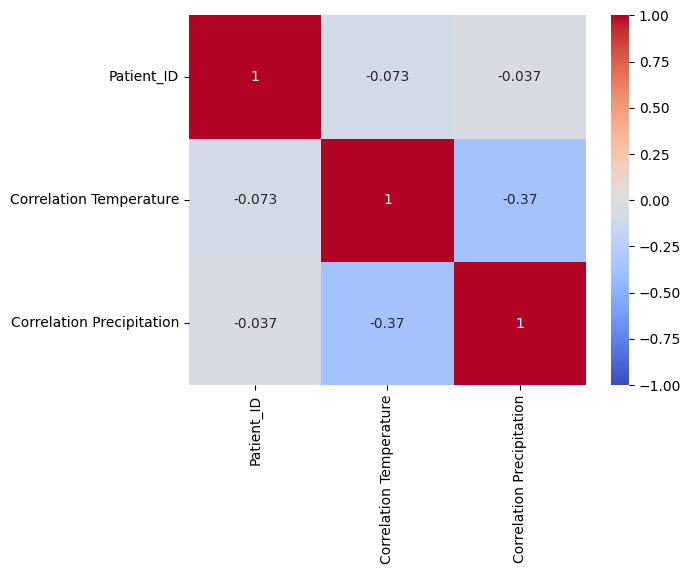

In [ ]:
import seaborn as sns

sns.heatmap(corr_df.corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
mpl.show()

In [ ]:
import plotly.express as px

fig_scatter = px.scatter(
    merged_df,
    x='Max_Temperature',
    y='steps',
    title=f'Daily Steps vs. Maximum Temperature for Patient {patient_id}',
    labels={
        'Max_Temperature': 'Maximum Temperature (°C)',
        'steps': 'Total Daily Steps'
    },
    hover_data=['Date']
)

fig_scatter.update_layout(
    height=500,
    showlegend=False
)

fig_scatter.show()

### Pollen

In [ ]:
correlation = merged_df['steps'].corr(merged_df['Max_Temperature'])
print(f"Correlation between Daily Steps and Maximum Temperature for Patient {patient_id}: {correlation:.4f}")

Correlation between Daily Steps and Maximum Temperature for Patient 1971: 0.1083


In [ ]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pandas as pd
import plotly.express as px

# Helper function to generate alternating day background shapes for a subplot
# def generate_alternating_day_background_shapes(df_subset, y_min, y_max, yref_target):
#     df_subset = df_subset.copy()
#     df_subset['time'] = pd.to_datetime(df_subset['time'])
#     df_subset = df_subset.sort_values(by='time').reset_index(drop=True)

#     dates = df_subset['time'].dt.normalize().unique()
#     colors = ['rgba(240, 240, 240, 0.5)', 'rgba(255, 255, 255, 0.5)']
#     current_color_idx = 0
#     shapes = []
#     for i in range(len(dates)):
#         start_day = dates[i]
#         end_day = start_day + pd.Timedelta(days=1)
#         shapes.append(go.layout.Shape(
#             type="rect",
#             xref="x", yref=yref_target,
#             x0=start_day,
#             y0=y_min,
#             x1=end_day,
#             y1=y_max,
#             fillcolor=colors[current_color_idx],
#             layer="below",
#             line_width=0,
#             opacity=1
#         ))
#         current_color_idx = 1 - current_color_idx
#     return shapes

# Define pollen columns based on pollen_data_df.columns, excluding 'Date'
pollen_columns = [col for col in pollen_data_df.columns if col != 'Date']

# Define grid dimensions (8 rows * 6 columns = 48 subplots)
rows = 8
cols = 6

# Create a single Plotly figure with subplots for steps and pollen
# Each subplot needs secondary_y for pollen data
specs = [[{"secondary_y": True}] * cols for _ in range(rows)]
fig_pollen = make_subplots(rows=rows, cols=cols, shared_xaxes=False, vertical_spacing=0.05, horizontal_spacing=0.02, specs=specs)

# Initialize DataFrame to store correlations
correlation_pollen_df = pd.DataFrame(columns=['Patient_ID'] + [f'Correlation Steps-{p}' for p in pollen_columns])

# Loop through each patient to add traces to the subplots
# Limit to the number of subplots available in the grid
for idx, patient_entry in enumerate(patients):
    patient_id = patient_entry['id']
    patient_data = patient_entry['data']

    current_row = (idx // cols) + 1
    current_col = (idx % cols) + 1

    # Process patient data for daily steps
    df_patient = patient_data.copy()
    df_patient['time'] = pd.to_datetime(df_patient['time'])
    daily_steps_df = df_patient.set_index('time').resample('D')['steps'].sum().reset_index()
    daily_steps_df.rename(columns={'time': 'Date'}, inplace=True)

    # Merge daily steps with pollen data - changed how='inner' to how='left'
    merged_pollen_df = pd.merge(daily_steps_df, pollen_data_df, on='Date', how='left')
    merged_pollen_df.sort_values(by='Date', inplace=True)

    print(merged_pollen_df['Date'][0].date())

    # Dictionary to store correlations for the current patient
    patient_correlations = {'Patient_ID': patient_id}

    if merged_pollen_df.empty:
        # Add a placeholder annotation for empty subplots
        fig_pollen.add_annotation(
            xref="x domain", yref="y domain",
            x=0.5, y=0.5, text=f"No data for {patient_id}", showarrow=False,
            row=current_row, col=current_col,
            font=dict(size=10, color="gray")
        )
        # Add NaN correlations for this patient
        for p_col in pollen_columns:
            patient_correlations[f'Correlation Steps-{p_col}'] = None
        correlation_pollen_df = pd.concat([correlation_pollen_df, pd.DataFrame([patient_correlations])], ignore_index=True)
        continue

    # # Generate and add alternating day backgrounds for this subplot (for steps) - commented out as per user request
    # bg_shapes_steps = generate_alternating_day_background_shapes(merged_pollen_df.rename(columns={'Date': 'time'}),
    #                                                            y_min=-500, y_max=30000, yref_target='y')
    # for shape in bg_shapes_steps:
    #     fig_pollen.add_shape(shape, row=current_row, col=current_col)


    # Add trace for daily steps (primary y-axis)
    fig_pollen.add_trace(
        go.Scatter(x=merged_pollen_df['Date'], y=merged_pollen_df['steps'], mode='lines',
                   name='Daily Steps', line=dict(color='blue'),
                   showlegend=(idx == 0)), # Show legend only for the first patient's steps trace
        row=current_row, col=current_col, secondary_y=False
    )

    # Add traces for each pollen type (secondary y-axis)
    pollen_colors = px.colors.qualitative.Plotly # Use a qualitative color scale for different pollen types
    for i, p_col in enumerate(pollen_columns):
        # Resolve RuntimeWarning: invalid value encountered in divide
        # Check if either series has zero standard deviation (is constant) before calculating correlation
        if merged_pollen_df['steps'].std() == 0 or merged_pollen_df[p_col].std() == 0 or merged_pollen_df['steps'].isnull().all() or merged_pollen_df[p_col].isnull().all():
            correlation = float('nan')
        else:
            correlation = merged_pollen_df['steps'].corr(merged_pollen_df[p_col])

        fig_pollen.add_trace(
            go.Scatter(x=merged_pollen_df['Date'], y=merged_pollen_df[p_col], mode='lines',
                       name=p_col, line=dict(color=pollen_colors[i % len(pollen_colors)]),
                       showlegend=(idx == 0)), # Show legend only for the first patient's pollen traces
            row=current_row, col=current_col, secondary_y=True
        )
        # Store correlation
        patient_correlations[f'Correlation Steps-{p_col}'] = round(correlation, 4)

    # Add patient's correlations to the DataFrame
    correlation_pollen_df = pd.concat([correlation_pollen_df, pd.DataFrame([patient_correlations])], ignore_index=True)

    # Set subplot title
    fig_pollen.add_annotation(
        x=0.5, y=1.0, xref="x domain", yref="y domain",
        text=f"Patient {patient_id}", showarrow=False,
        font=dict(size=10), yshift=10,
        row=current_row, col=current_col
    )

    # Update layout for this specific subplot
    # Add first and last date on each x-axis
    fig_pollen.update_xaxes(
        showticklabels=True,
        tickvals=[merged_pollen_df['Date'].iloc[0], merged_pollen_df['Date'].iloc[-1]],
        ticktext=[merged_pollen_df['Date'].iloc[0].strftime('%d %month %Y'), merged_pollen_df['Date'].iloc[-1].strftime('%d %m %Y')],
        tickangle=-45,
        row=current_row,
        col=current_col
        )
    fig_pollen.update_yaxes(title_text='Steps', secondary_y=False, range=[-500, 30000], row=current_row, col=current_col, showticklabels=True)
    fig_pollen.update_yaxes(title_text='Pollen', secondary_y=True, range=[0, 500], row=current_row, col=current_col, showticklabels=True)

    # Add common y-axis labels to the first column and last column for clarity
    if current_col == 1:
        fig_pollen.update_yaxes(title_text='Total Steps per Day', secondary_y=False, showticklabels=True, row=current_row, col=current_col)
    if current_col == cols: # Only on the last column
        fig_pollen.update_yaxes(title_text='Pollen Count', secondary_y=True, showticklabels=True, row=current_row, col=current_col)


# Update overall figure layout
fig_pollen.update_layout(
    height=300 * rows,
    width=300 * cols,
    title_text='Daily Steps and Pollen Count for All Patients',
    hovermode='x unified',
    showlegend=True, # Show legend for all traces by default from first patient
    legend=dict(
        x=1.02, y=1,
        bgcolor='rgba(255, 255, 255, 0.8)',
        bordercolor='rgba(0, 0, 0, 0.2)',
        orientation='v' # Vertical legend
    )
)

fig_pollen.show()

# Display the correlation table
print("\nCorrelation between Daily Steps and Pollen Count for Each Patient:")
display(correlation_pollen_df)

# Generate and display the correlation heatmap
print("\nCorrelation Heatmap:")
heatmap_data = correlation_pollen_df.set_index('Patient_ID').copy()

# Ensure all values are numeric, coerce errors to NaN
for col in heatmap_data.columns:
    heatmap_data[col] = pd.to_numeric(heatmap_data[col], errors='coerce')

# Drop rows where all correlation values are NaN (patients with no overlapping data)
heatmap_data.dropna(how='all', inplace=True)

if not heatmap_data.empty:
    fig_heatmap = px.imshow(heatmap_data,
                            labels=dict(x="Pollen Type", y="Patient ID", color="Correlation"),
                            x=heatmap_data.columns,
                            y=heatmap_data.index,
                            color_continuous_scale='RdBu_r', # Red-Blue diverging colormap
                            range_color=[-1, 1], # Set color range for correlations
                            title="Correlation Heatmap: Daily Steps vs. Pollen Count per Patient")

    fig_heatmap.update_layout(height=800, width=1200)
    fig_heatmap.show()
else:
    print("No sufficient data to generate correlation heatmap.")

2021-09-02
2021-09-21
2021-01-08
2021-02-05
2021-08-09
2021-02-09
2021-08-23


/tmp/ipykernel_2771/2647065232.py:122: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.



2021-06-08
2021-01-18
2021-09-27
2021-02-05
2021-09-02
2021-06-21
2021-04-21
2021-04-14
2021-06-01
2021-04-28
2021-06-08
2021-09-14
2021-02-18
2021-03-23
2021-05-26
2021-04-21
2021-04-28
2021-08-31
2021-02-13
2021-04-09
2021-04-15
2021-03-10
2021-07-27
2021-08-19
2021-05-04
2021-03-24
2021-05-04
2021-09-08
2021-03-30
2021-08-03
2021-03-02
2021-02-02
2021-09-14
2021-06-01
2021-06-14
2021-07-06



Correlation between Daily Steps and Pollen Count for Each Patient:


,Patient_ID,Correlation Steps-Alder,Correlation Steps-Birch,Correlation Steps-Hazel,Correlation Steps-Beech,Correlation Steps-Common ash,Correlation Steps-Oak,Correlation Steps-Grasses
0,1971,NaN,0.1001,NaN,NaN,NaN,NaN,-0.2322
1,8046,NaN,NaN,NaN,NaN,NaN,NaN,-0.3242
2,3389,-0.0408,-0.0566,-0.2290,NaN,-0.0725,NaN,0.2214
3,9173,-0.0879,-0.0508,0.1861,NaN,-0.0658,-0.0559,-0.0524
4,2676,0.1493,0.0346,NaN,NaN,NaN,NaN,-0.1692
5,9085,0.4079,-0.2163,0.5667,NaN,-0.2682,NaN,0.0138
6,7016,NaN,-0.1409,NaN,NaN,NaN,NaN,0.4002
7,4475,0.0725,-0.0773,0.0553,-0.0735,NaN,NaN,0.2144
8,4349,0.3169,-0.0054,0.2288,NaN,0.2400,NaN,-0.0790
9,5977,NaN,NaN,NaN,NaN,NaN,NaN,0.0906



Correlation Heatmap:


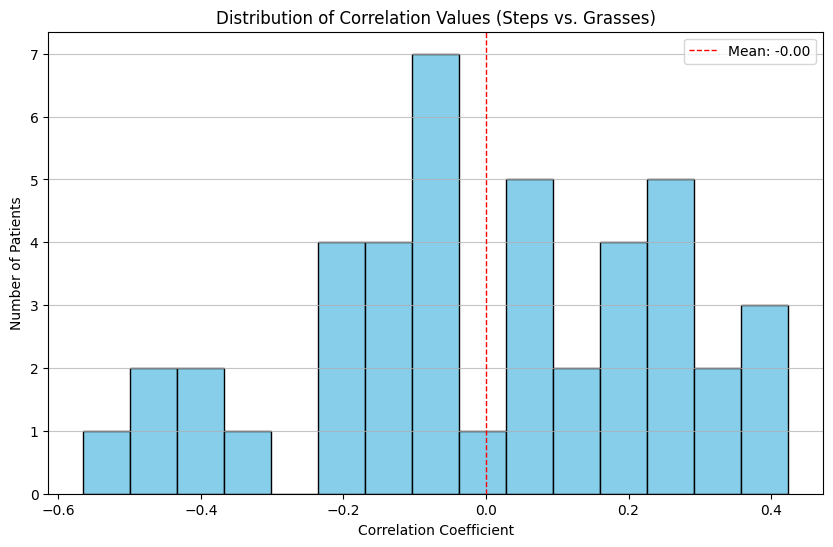

In [ ]:
import matplotlib.pyplot as plt

# Choose a pollen type to visualize its correlations
pollen_type = 'Grasses' # @param ['Alder', 'Birch', 'Hazel', 'Beech', 'Common ash', 'Oak', 'Grasses'] {type:'string'}

correlation_column = f'Correlation Steps-{pollen_type}'

# Drop NaN values before plotting the histogram
valid_correlations = correlation_pollen_df[correlation_column].dropna()

if not valid_correlations.empty:
    plt.figure(figsize=(10, 6))
    plt.hist(valid_correlations, bins=15, edgecolor='black', color='skyblue')
    plt.title(f'Distribution of Correlation Values (Steps vs. {pollen_type})')
    plt.xlabel('Correlation Coefficient')
    plt.ylabel('Number of Patients')
    plt.grid(axis='y', alpha=0.75)
    plt.axvline(valid_correlations.mean(), color='red', linestyle='dashed', linewidth=1, label=f'Mean: {valid_correlations.mean():.2f}')
    plt.legend()
    plt.show()
else:
    print(f"No valid correlation data found for '{pollen_type}' to plot a histogram.")

# Hypothesis 2
Age and disease stage on movement

## Reading patient information

In [ ]:
patient_information_df = pd.read_csv('/content/drive/My Drive/Colab Notebooks/IVDA/ClinicalMarkers_final.csv', index_col='Record', header=0, names=['Record', 'Age', 'Sex', 'Disease Type', 'Id'])
# patient_information_df.rename(columns={'\"disease.type"': 'Disease Type'}, inplace=True)
patient_information_df = patient_information_df[patient_information_df['Id'] != 4063]
print(patient_information_df.head(), '\n\n', patient_information_df.describe())
#
# print(os.listdir('/content/drive/My Drive/Colab Notebooks/IVDA/'))

         Age     Sex         Disease Type    Id
Record                                         
1       1971  Female   Late Disease Stage  3389
2       1997  Female  Early Disease Stage  4349
3       1981  Female   Late Disease Stage  6155
4       1973  Female  Early Disease Stage  9173
5       1981  Female  Early Disease Stage  2815 

                Age           Id
count    43.000000    43.000000
mean   1977.790698  5822.790698
std       8.808973  2484.076695
min    1958.000000  1120.000000
25%    1972.500000  3877.000000
50%    1978.000000  6155.000000
75%    1982.500000  7962.000000
max    2005.000000  9926.000000


## Calculating

In [ ]:
average_daily_steps = []

for patient_entry in patients:
    patient_id = patient_entry['id']
    df_patient = patient_entry['data'].copy()

    # Convert 'time' column to datetime objects
    df_patient['time'] = pd.to_datetime(df_patient['time'])

    # Calculate daily total steps
    daily_steps = df_patient.set_index('time').resample('D')['steps'].sum().reset_index()

    # Calculate average daily steps
    if not daily_steps.empty:
        avg_steps = int(daily_steps['steps'].mean())
        average_daily_steps.append({'Id': int(patient_id), 'Average_Daily_Steps': avg_steps})
    else:
        average_daily_steps.append({'Id': int(patient_id), 'Average_Daily_Steps': None})

# print(average_daily_steps)

# Convert the list of dictionaries to a DataFrame
avg_steps_df = pd.DataFrame(average_daily_steps)

# print(avg_steps_df.head())

# # Ensure the 'Id' column in patient_information_df is numeric for merging
patient_information_df['Id'] = pd.to_numeric(patient_information_df['Id'], errors='coerce')

# print(patient_information_df.head())

# # Merge with patient_information_df
patient_avg_steps_df = pd.merge(patient_information_df, avg_steps_df, on='Id', how='left')

print("Patient Information with Average Daily Steps:")
print(patient_avg_steps_df.head())
print(patient_avg_steps_df.describe())



Patient Information with Average Daily Steps:
    Age     Sex         Disease Type    Id  Average_Daily_Steps
0  1971  Female   Late Disease Stage  3389                 5709
1  1997  Female  Early Disease Stage  4349                 9902
2  1981  Female   Late Disease Stage  6155                 7542
3  1973  Female  Early Disease Stage  9173                 5496
4  1981  Female  Early Disease Stage  2815                10346
               Age           Id  Average_Daily_Steps
count    43.000000    43.000000            43.000000
mean   1977.790698  5822.790698          7186.488372
std       8.808973  2484.076695          3552.012725
min    1958.000000  1120.000000          2140.000000
25%    1972.500000  3877.000000          4663.000000
50%    1978.000000  6155.000000          6798.000000
75%    1982.500000  7962.000000          9508.000000
max    2005.000000  9926.000000         16735.000000


## Bars

In [ ]:
import plotly.express as px

# Group by 'disease.type' and calculate the mean of 'Average_Daily_Steps'
disease_type_avg_steps = patient_avg_steps_df.groupby('Disease Type')['Average_Daily_Steps'].mean().reset_index()
print(disease_type_avg_steps)

# Create the bar chart
fig = px.bar(
    disease_type_avg_steps,
    x='Disease Type',
    y='Average_Daily_Steps',
    title='Average Daily Steps Grouped by Disease Type',
    # labels={
    #     '"disease.type"': 'Disease Type',
    #     'Average_Daily_Steps': 'Average Daily Steps'
    # },
    color='Disease Type' # Differentiate bars by color
)

fig.update_layout(
    xaxis_title_text='Disease Type',
    yaxis_title_text='Average Daily Steps',
    hovermode='x unified'
)

fig.show()

               Disease Type  Average_Daily_Steps
0       Early Disease Stage          8885.764706
1  Fast Disease Progression          7142.285714
2        Late Disease Stage          5682.368421


## Heatmap

In [ ]:
import plotly.express as px

# Heatmap for Age and Average_Daily_Steps
# Select relevant columns and drop rows with NaN in these columns for correlation calculation
df_age_steps = patient_avg_steps_df[['Age', 'Average_Daily_Steps']].dropna()

print("Generating Correlation Heatmap: Age vs. Average Daily Steps...")
if not df_age_steps.empty:
    correlation_matrix_age_steps = df_age_steps.corr()
    print(correlation_matrix_age_steps)

    fig_age_steps = px.imshow(correlation_matrix_age_steps,
                              text_auto=True,
                              title='Correlation Heatmap: Age vs. Average Daily Steps',
                              color_continuous_scale='RdBu_r', # Red-Blue diverging colormap
                              range_color=[-1, 1]) # Set color range for correlations
    fig_age_steps.show()
else:
    print("Not enough valid data to calculate correlation for Age and Average Daily Steps.")

Generating Correlation Heatmap: Age vs. Average Daily Steps...
                          Age  Average_Daily_Steps
Age                  1.000000             0.373924
Average_Daily_Steps  0.373924             1.000000


In [ ]:
import plotly.express as px
import pandas as pd

# Heatmap for Disease Type and Average_Daily_Steps
df_disease_steps = patient_avg_steps_df[['Disease Type', 'Average_Daily_Steps']].dropna()

print("Generating Correlation Heatmap: Average Daily Steps vs. Disease Type...")
if not df_disease_steps.empty:
    # One-hot encode 'Disease Type'
    df_encoded = pd.get_dummies(df_disease_steps, columns=['Disease Type'], prefix='Disease')

    # Calculate correlations between Average_Daily_Steps and each encoded disease type
    # We are interested in correlations of 'Average_Daily_Steps' with the dummy variables
    correlation_with_dummies = df_encoded.corr()['Average_Daily_Steps'].drop('Average_Daily_Steps')

    # Convert the Series to a DataFrame suitable for px.imshow (single row)
    correlation_df_for_heatmap = pd.DataFrame(correlation_with_dummies).transpose()
    # Clean up column names for better display
    correlation_df_for_heatmap.columns = [col.replace('Disease_', '') for col in correlation_df_for_heatmap.columns]
    correlation_df_for_heatmap.index = ['Average_Daily_Steps'] # Give a meaningful index for the single row

    fig_disease_steps = px.imshow(correlation_df_for_heatmap,
                                  text_auto=True,
                                  title='Correlation Heatmap: Average Daily Steps vs. Disease Type',
                                  color_continuous_scale='RdBu_r',
                                  range_color=[-1, 1],
                                  labels=dict(x="Disease Type", y="Variable", color="Correlation"))
    fig_disease_steps.show()
else:
    print("Not enough valid data to calculate correlation for Disease Type and Average Daily Steps.")

Generating Correlation Heatmap: Average Daily Steps vs. Disease Type...


In [ ]:
import plotly.express as px

# Create the scatter plot
fig = px.scatter(
    patient_avg_steps_df,
    x='Age',
    y='Average_Daily_Steps',
    color='Disease Type', # Color points by 'Disease Type'
    title='Age vs. Average Daily Steps (Colored by Disease Type)',
    labels={
        'Age': 'Age',
        'Average_Daily_Steps': 'Average Daily Steps',
        'Disease Type': 'Disease Type'
    },
    hover_data=['Id', 'Sex'] # Show patient ID and Sex on hover
)

fig.update_traces(marker=dict(size=10)) # Increase point size for better visibility

fig.update_layout(
    xaxis_title_text='Age',
    yaxis_title_text='Average Daily Steps',
    hovermode='closest' # Better hover experience for scatter plots
)

fig.show()

## Multivariate Regression: Age and Disease Type on Average Daily Steps

In [ ]:
import statsmodels.api as sm
import pandas as pd

# Prepare the data for regression
# One-hot encode 'Disease Type'
df_regression = pd.get_dummies(patient_avg_steps_df, columns=['Disease Type'], prefix='Disease')

# Define the dependent variable (y) and independent variables (X)
y = df_regression['Average_Daily_Steps'].dropna() # Remove NaNs from target variable

# Select independent variables: 'Age' and the one-hot encoded 'Disease Type' columns
X_cols = ['Age'] + [col for col in df_regression.columns if col.startswith('Disease_')]
X = df_regression[X_cols]

# Ensure X and y have matching indices after dropping NaNs
X = X.loc[y.index]

# Convert boolean columns to integers (True to 1, False to 0) for statsmodels
for col in X.columns:
    if X[col].dtype == bool:
        X[col] = X[col].astype(int)

# Add a constant to the independent variables for the intercept term
X = sm.add_constant(X)

# Create and fit the OLS (Ordinary Least Squares) model
model = sm.OLS(y, X)
results = model.fit()

# Print the regression summary
print(results.summary())


                             OLS Regression Results                            
Dep. Variable:     Average_Daily_Steps   R-squared:                       0.219
Model:                             OLS   Adj. R-squared:                  0.159
Method:                  Least Squares   F-statistic:                     3.654
Date:                 Sun, 31 May 2026   Prob (F-statistic):             0.0205
Time:                         21:08:07   Log-Likelihood:                -406.72
No. Observations:                   43   AIC:                             821.4
Df Residuals:                       39   BIC:                             828.5
Df Model:                            3                                         
Covariance Type:             nonrobust                                         
                                       coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------

In [ ]:
import numpy as np

# Extract the R-squared value from the regression results
r_squared = results.rsquared

# Calculate the multiple correlation coefficient (R)
multiple_r = np.sqrt(r_squared)

print(f"The R-squared value is: {r_squared:.4f}")
print(f"The multiple correlation coefficient (R) is: {multiple_r:.4f}")


The R-squared value is: 0.2205
The multiple correlation coefficient (R) is: 0.4695


## Re-calculating Multiple Correlation Coefficient (without using previous OLS results)

In [ ]:
import statsmodels.api as sm
import pandas as pd
import numpy as np

# Prepare the data for regression (same as before)
df_regression_new = pd.get_dummies(patient_avg_steps_df, columns=['Disease Type'], prefix='Disease')

# Define the dependent variable (y) and independent variables (X)
y_new = df_regression_new['Average_Daily_Steps'].dropna()

X_cols_new = ['Age'] + [col for col in df_regression_new.columns if col.startswith('Disease_')]
X_new = df_regression_new[X_cols_new]

# Ensure X and y have matching indices after dropping NaNs
X_new = X_new.loc[y_new.index]

# Convert boolean columns to integers for statsmodels
for col in X_new.columns:
    if X_new[col].dtype == bool:
        X_new[col] = X_new[col].astype(int)

# Add a constant to the independent variables for the intercept term
X_new = sm.add_constant(X_new)

# Create and fit a NEW OLS model
model_new = sm.OLS(y_new, X_new)
results_new = model_new.fit()

# Extract the R-squared value from these new regression results
r_squared_new = results_new.rsquared

# Calculate the multiple correlation coefficient (R)
multiple_r_new = np.sqrt(r_squared_new)

print(f"The R-squared value from the new OLS results is: {r_squared_new:.4f}")
print(f"The multiple correlation coefficient (R) calculated from new OLS results is: {multiple_r_new:.4f}")


The R-squared value from the new OLS results is: 0.2194
The multiple correlation coefficient (R) calculated from new OLS results is: 0.4684


# thrid hypothesis

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import plotly.express as px

# 1. Convert 'Age' (birth year) to actual age. Assuming data collected around 2021.
current_year = 2021 # Based on the timestamps in the sensor data
patient_avg_steps_df['Age_in_Years'] = current_year - patient_avg_steps_df['Age']

# 2. Select features for clustering
features = ['Age_in_Years', 'Average_Daily_Steps']
df_clustering = patient_avg_steps_df[features].dropna().copy() # Drop rows with NaN in selected features

# 3. Standardize the features
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_clustering)

# Convert back to DataFrame for easier handling, keeping original index
df_scaled = pd.DataFrame(df_scaled, columns=features, index=df_clustering.index)

# 4. Apply K-Means clustering
# Let's start with 3 clusters, but in a real scenario, you'd determine k using methods like the Elbow Method or Silhouette Score.
n_clusters = 3
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10) # n_init=10 for robustness
cluster_labels = kmeans.fit_predict(df_scaled)

# 5. Add cluster labels back to the original (non-scaled) DataFrame
df_clustering['Cluster'] = cluster_labels

# Assign cluster labels to the main patient_avg_steps_df, aligning by index
# Patients not in df_clustering (due to NaNs in features) will get NaN for 'Cluster'
patient_avg_steps_df['Cluster'] = df_clustering['Cluster']

# 6. Visualize the clusters
# Only plot rows where 'Cluster' is not NaN (i.e., successfully clustered patients)
plot_df = patient_avg_steps_df.dropna(subset=['Cluster']).copy() # Use .copy() to avoid SettingWithCopyWarning
plot_df['Cluster'] = plot_df['Cluster'].astype(str) # Convert cluster labels to string for discrete colors in Plotly Express

fig = px.scatter(
    plot_df,
    x='Age_in_Years',
    y='Average_Daily_Steps',
    color='Cluster', # Color points by the assigned cluster
    title='Patient Clusters based on Age and Average Daily Steps',
    labels={
        'Age_in_Years': 'Age (Years)',
        'Average_Daily_Steps': 'Average Daily Steps'
    },
    hover_data=['Id', 'Sex', 'Disease Type'] # Show additional info on hover
)

fig.update_layout(
    xaxis_title_text='Age (Years)',
    yaxis_title_text='Average Daily Steps',
    hovermode='closest'
)

fig.show()

print("Patients assigned to clusters:")
print(patient_avg_steps_df[['Id', 'Age_in_Years', 'Average_Daily_Steps', 'Disease Type', 'Cluster']].head())
print(patient_avg_steps_df['Cluster'].value_counts())

# 7. Calculate and print the Silhouette Score
# Ensure there are enough clustered samples and more than one cluster
if len(df_scaled) > 1 and n_clusters > 1 and n_clusters < len(df_scaled):
    silhouette_avg = silhouette_score(df_scaled, cluster_labels)
    print(f"\nSilhouette Score for {n_clusters} clusters: {silhouette_avg:.4f}")
else:
    print("\nCannot compute Silhouette Score: Not enough data points or invalid number of clusters.")

Patients assigned to clusters:
     Id  Age_in_Years  Average_Daily_Steps         Disease Type  Cluster
0  3389            50                 5709   Late Disease Stage        1
1  4349            24                 9902  Early Disease Stage        2
2  6155            40                 7542   Late Disease Stage        2
3  9173            48                 5496  Early Disease Stage        1
4  2815            40                10346  Early Disease Stage        0
Cluster
1    20
2    14
0     9
Name: count, dtype: int64

Silhouette Score for 3 clusters: 0.4437


## Correlation between Daily Steps and Sleep Minutes

In [ ]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pandas as pd
import plotly.express as px
import numpy as np

# Helper function to generate alternating day background shapes for a subplot
def add_alternating_day_backgrounds_plotly_steps_sleep(fig, df_subset, y_min_steps, y_max_steps):
    df_subset = df_subset.copy()
    df_subset['Date'] = pd.to_datetime(df_subset['Date'])
    df_subset = df_subset.sort_values(by='Date').reset_index(drop=True)

    dates = df_subset['Date'].dt.normalize().unique()
    colors = ['rgba(240, 240, 240, 0.5)', 'rgba(255, 255, 255, 0.5)']
    current_color_idx = 0
    shapes = []
    for i in range(len(dates)):
        start_day = dates[i]
        end_day = start_day + pd.Timedelta(days=1)
        shapes.append(go.layout.Shape(
            type="rect",
            xref="x", yref="y",
            x0=start_day,
            y0=y_min_steps,
            x1=end_day,
            y1=y_max_steps,
            fillcolor=colors[current_color_idx],
            layer="below",
            line_width=0,
            opacity=1
        ))
        current_color_idx = 1 - current_color_idx
    fig.update_layout(shapes=list(fig.layout.shapes) + shapes)

# Define grid dimensions (8 rows * 6 columns = 48 subplots)
rows = 8
cols = 6

# Create a single Plotly figure with subplots for steps and sleep
# Each subplot needs secondary_y for sleep data
specs = [[{"secondary_y": True}] * cols for _ in range(rows)]
fig_sleep = make_subplots(rows=rows, cols=cols, shared_xaxes=False, vertical_spacing=0.05, horizontal_spacing=0.02, specs=specs)

# Initialize DataFrame to store correlations
correlation_sleep_df = pd.DataFrame(columns=['Patient_ID', 'Correlation Steps-Sleep Minutes'])

# Determine global max steps and max sleep minutes for consistent y-axis scaling
global_max_steps = 0
global_max_sleep_minutes = 0

for patient_entry in patients:
    df_patient = patient_entry['data'].copy()
    df_patient['time'] = pd.to_datetime(df_patient['time'])

    # Calculate max steps for this patient
    daily_steps_temp = df_patient.set_index('time').resample('D')['steps'].sum().max()
    if daily_steps_temp > global_max_steps:
        global_max_steps = daily_steps_temp

    # Calculate max sleep minutes for this patient
    daily_sleep_minutes = []
    unique_dates = df_patient['time'].dt.normalize().unique()
    for ref_date in unique_dates:
        start_time = ref_date - pd.Timedelta(days=1) + pd.Timedelta(hours=22) # Changed from 2 to 22
        end_time = ref_date + pd.Timedelta(hours=10)
        sleep_interval_df = df_patient[(df_patient['time'] >= start_time) & (df_patient['time'] <= end_time)]
        total_sleep_hours = sleep_interval_df['sleep'].sum()
        daily_sleep_minutes.append({'Date': ref_date, 'Sleep_Minutes': total_sleep_hours * 60})
    daily_sleep_minutes_df_temp = pd.DataFrame(daily_sleep_minutes)
    if not daily_sleep_minutes_df_temp.empty:
        current_max_sleep_minutes = daily_sleep_minutes_df_temp['Sleep_Minutes'].max()
        if current_max_sleep_minutes > global_max_sleep_minutes:
            global_max_sleep_minutes = current_max_sleep_minutes

# Loop through each patient to add traces to the subplots
for idx, patient_entry in enumerate(patients):
    patient_id = patient_entry['id']
    patient_data = patient_entry['data']

    current_row = (idx // cols) + 1
    current_col = (idx % cols) + 1

    # Process patient data for daily steps
    df_patient = patient_data.copy()
    df_patient['time'] = pd.to_datetime(df_patient['time'])
    daily_steps_df = df_patient.set_index('time').resample('D')['steps'].sum().reset_index()
    daily_steps_df.rename(columns={'time': 'Date'}, inplace=True)

    # Process patient data for daily sleep minutes
    daily_sleep_minutes = []
    unique_dates = df_patient['time'].dt.normalize().unique()
    for ref_date in unique_dates:
        start_time = ref_date - pd.Timedelta(days=1) + pd.Timedelta(hours=22) # Changed from 2 to 22
        end_time = ref_date + pd.Timedelta(hours=10)
        sleep_interval_df = df_patient[(df_patient['time'] >= start_time) & (df_patient['time'] <= end_time)]
        total_sleep_hours = sleep_interval_df['sleep'].sum()
        daily_sleep_minutes.append({'Date': ref_date, 'Sleep_Minutes': total_sleep_hours * 60})
    daily_sleep_minutes_df = pd.DataFrame(daily_sleep_minutes)

    # Merge daily steps with daily sleep minutes
    merged_sleep_df = pd.merge(daily_steps_df, daily_sleep_minutes_df, on='Date', how='inner')
    merged_sleep_df.sort_values(by='Date', inplace=True)

    # Calculate correlation
    correlation_sleep = np.nan # Initialize as NaN
    if not merged_sleep_df.empty and merged_sleep_df['steps'].std() > 0 and merged_sleep_df['Sleep_Minutes'].std() > 0:
        correlation_sleep = merged_sleep_df['steps'].corr(merged_sleep_df['Sleep_Minutes'])

    correlation_sleep_df = pd.concat([correlation_sleep_df, pd.DataFrame([{'Patient_ID': patient_id, 'Correlation Steps-Sleep Minutes': round(correlation_sleep, 4)}])], ignore_index=True)

    # Add trace for daily steps (primary y-axis)
    fig_sleep.add_trace(
        go.Scatter(x=merged_sleep_df['Date'], y=merged_sleep_df['steps'], mode='lines', name='Daily Steps', line=dict(color='blue'), showlegend=(idx == 0)),
        row=current_row, col=current_col, secondary_y=False
    )

    # Add trace for daily sleep minutes (secondary y-axis)
    fig_sleep.add_trace(
        go.Scatter(x=merged_sleep_df['Date'], y=merged_sleep_df['Sleep_Minutes'], mode='lines', name='Sleep Minutes', line=dict(color='purple'), showlegend=(idx == 0)),
        row=current_row, col=current_col, secondary_y=True
    )

    # Add alternating day backgrounds for steps
    add_alternating_day_backgrounds_plotly_steps_sleep(fig_sleep, merged_sleep_df, y_min_steps=-global_max_steps*0.1, y_max_steps=global_max_steps*1.1)

    # Set subplot title
    fig_sleep.add_annotation(
        x=0.5, y=1.0, xref="x domain", yref="y domain",
        text=f"Patient {patient_id}", showarrow=False,
        font=dict(size=10), yshift=10,
        row=current_row, col=current_col
    )

    # Update layout for this specific subplot
    fig_sleep.update_xaxes(
        showticklabels=True, # Show tick labels for all subplots
        tickvals=[merged_sleep_df['Date'].iloc[0], merged_sleep_df['Date'].iloc[-1]] if not merged_sleep_df.empty else [],
        ticktext=[merged_sleep_df['Date'].iloc[0].strftime('%d %m %Y'), merged_sleep_df['Date'].iloc[-1].strftime('%d %m %Y')] if not merged_sleep_df.empty else [],
        tickangle=-45,
        row=current_row, col=current_col
    )
    fig_sleep.update_yaxes(title_text='Steps', secondary_y=False, range=[-global_max_steps*0.1, global_max_steps*1.1], row=current_row, col=current_col, showticklabels=True)
    fig_sleep.update_yaxes(title_text='Sleep (Minutes)', secondary_y=True, range=[-global_max_sleep_minutes*0.1, global_max_sleep_minutes*1.1], row=current_row, col=current_col, showticklabels=True)

    # Add common y-axis labels to the first column and last column for clarity
    if current_col == 1:
        fig_sleep.update_yaxes(title_text='Total Steps per Day', secondary_y=False, showticklabels=True, row=current_row, col=current_col)
    if current_col == cols:
        fig_sleep.update_yaxes(title_text='Sleep Minutes', secondary_y=True, showticklabels=True, row=current_row, col=current_col)

# Update overall figure layout
fig_sleep.update_layout(
    height=300 * rows,
    width=300 * cols,
    title_text='Daily Steps and Sleep Minutes for All Patients',
    hovermode='x unified',
    showlegend=True,
    legend=dict(
        x=1.02, y=1,
        bgcolor='rgba(255, 255, 255, 0.8)',
        bordercolor='rgba(0, 0, 0, 0.2)',
        orientation='v'
    )
)

fig_sleep.show()

# Display the correlation table
print("\nCorrelation between Daily Steps and Sleep Minutes for Each Patient:")
display(correlation_sleep_df)

# Generate and display the correlation heatmap
print("\nCorrelation Heatmap (Daily Steps vs. Sleep Minutes):")
heatmap_sleep_data = correlation_sleep_df.set_index('Patient_ID').copy()

# Ensure all values are numeric, coerce errors to NaN
for col in heatmap_sleep_data.columns:
    heatmap_sleep_data[col] = pd.to_numeric(heatmap_sleep_data[col], errors='coerce')

# Drop rows where all correlation values are NaN (patients with no overlapping data)
heatmap_sleep_data.dropna(how='all', inplace=True)

if not heatmap_sleep_data.empty:
    fig_heatmap_sleep = px.imshow(heatmap_sleep_data,
                                labels=dict(x="Variable", y="Patient ID", color="Correlation"),
                                x=heatmap_sleep_data.columns,
                                y=heatmap_sleep_data.index,
                                color_continuous_scale='RdBu_r',
                                range_color=[-1, 1],
                                title="Correlation Heatmap: Daily Steps vs. Sleep Minutes per Patient")

    fig_heatmap_sleep.update_layout(height=800, width=400) # Adjust width as there's only one correlation column
    fig_heatmap_sleep.show()
else:
    print("No sufficient data to generate sleep correlation heatmap.")

import matplotlib.pyplot as plt

# Choose the correlation column
correlation_column_sleep = 'Correlation Steps-Sleep Minutes'

# Drop NaN values before plotting the histogram
valid_correlations_sleep = correlation_sleep_df[correlation_column_sleep].dropna()

if not valid_correlations_sleep.empty:
    plt.figure(figsize=(10, 6))
    plt.hist(valid_correlations_sleep, bins=15, edgecolor='black', color='lightcoral')
    plt.title(f'Distribution of Correlation Values (Steps vs. Sleep Minutes)')
    plt.xlabel('Correlation Coefficient')
    plt.ylabel('Number of Patients')
    plt.grid(axis='y', alpha=0.75)
    plt.axvline(valid_correlations_sleep.mean(), color='red', linestyle='dashed', linewidth=1, label=f'Mean: {valid_correlations_sleep.mean():.2f}')
    plt.legend()
    plt.show()
else:
    print(f"No valid correlation data found for '{correlation_column_sleep}' to plot a histogram.")


/tmp/ipykernel_3227/712544028.py:109: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.


KeyboardInterrupt

